# Does Having More Followers Lead to Higher Engagement on Bluesky?
##### Name: Sara Virgüez Calderón
##### Date: October 17, 2026
##### Course: EMAT

## Research Question

Is there a relationship between the number of followers a Bluesky account has and the average number of likes its posts receive?
My hypothesis is that accounts with more followers will get more likes on average because they have a larger audience.

## Theoretical and Statistical Applications

In social media marketing, having more followers can help an account reach more people, but that doesn't always mean it will get more likes.

For this project, I want to compare the number of followers with the average likes per post to see if they are related.

## Variables
- Independent variable: Number of followers per account.
- Dependent variable: Average number of likes per post.
- Unit of analysis: Bluesky account.

# Data Sources and API Endpoints

For this project, I'm using two endpoints from the Bluesky API.

The first one is app.bsky.actor.getProfile, which gives me information about an account, including its number of followers.

The second one is app.bsky.feed.getAuthorFeed, which lets me get posts from an account and see how many likes they received.

I chose these two because I need both the follower count and the likes to compare them.

One limitation is that the number of followers and likes can change over time. Also, I'm only looking at a small number of accounts, so the results might not represent everyone on Bluesky.


In [3]:

import requests
import pandas as pd
import matplotlib.pyplot as plt

base_url = "https://public.api.bsky.app/xrpc/"

endpoint = "app.bsky.actor.getProfile"

params = {
    "actor": "nytimes.com"
}

response = requests.get(
    base_url + endpoint,
    params=params,
    timeout=20
)

response.raise_for_status()

profile_data = response.json()

print("Account:", profile_data["handle"])
print("Followers:", profile_data["followersCount"])


Account: nytimes.com
Followers: 1352930


In [6]:

endpoint = "app.bsky.feed.getAuthorFeed"

params = {
    "actor": "nytimes.com",
    "limit": 10
}

response = requests.get(
    base_url + endpoint,
    params=params
)

if response.status_code == 200:
    feed_data = response.json()
    print(feed_data["feed"])
else:
    print("Error:", response.status_code)


[{'post': {'uri': 'at://did:plc:eclio37ymobqex2ncko63h4r/app.bsky.feed.post/3myg5s77po22z', 'cid': 'bafyreicb4fw26c25b5ch2icir36nd3vb6ul2opos6a27df7ucem6odnbs4', 'author': {'did': 'did:plc:eclio37ymobqex2ncko63h4r', 'handle': 'nytimes.com', 'displayName': 'The New York Times', 'avatar': 'https://cdn.bsky.app/img/avatar/plain/did:plc:eclio37ymobqex2ncko63h4r/bafkreidvvqj5jymmpaeklwkpq6gi532el447mjy2yultuukypzqm5ohfju', 'associated': {'chat': {'allowIncoming': 'none', 'allowGroupInvites': 'none'}, 'activitySubscription': {'allowSubscriptions': 'followers'}}, 'labels': [], 'createdAt': '2023-06-05T18:50:31.498Z', 'verification': {'verifications': [{'issuer': 'did:plc:z72i7hdynmk6r22z27h6tvur', 'issuerDisplayName': 'Bluesky', 'issuerHandle': 'bsky.app', 'uri': 'at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky.graph.verification/3lndptszmee2u', 'isValid': True, 'createdAt': '2025-04-21T10:46:44.369Z'}], 'verifiedStatus': 'valid', 'trustedVerifierStatus': 'valid'}}, 'record': {'$type': 'app.bs

In [7]:

posts = feed_data["feed"]

likes = []

for item in posts:
    likes.append(item["post"]["likeCount"])

df_likes = pd.DataFrame({
    "Likes": likes
})

df_likes


,Likes
0,8
1,37
2,66
3,33
4,54
5,168
6,91
7,75
8,374
9,33


In [8]:

average_likes = df_likes["Likes"].mean()

print("Average likes:", average_likes)


Average likes: 93.9


In [9]:

df_profile = pd.DataFrame({
    "Account": [profile_data["handle"]],
    "Followers": [profile_data["followersCount"]]
})

df_profile


,Account,Followers
0,nytimes.com,1352930


In [10]:

accounts = [
    "nytimes.com",
    "theguardian.com",
    "washingtonpost.com",
    "apnews.com",
    "npr.org",
    "bbc.com",
    "reuters.com",
    "theatlantic.com"
]

profiles = []
posts = []

for account in accounts:

    profile_response = requests.get(
        base_url + "app.bsky.actor.getProfile",
        params={"actor": account}
    )

    feed_response = requests.get(
        base_url + "app.bsky.feed.getAuthorFeed",
        params={
            "actor": account,
            "limit": 30,
            "filter": "posts_no_replies"
        }
    )

    if profile_response.status_code == 200 and feed_response.status_code == 200:

        profile = profile_response.json()
        feed = feed_response.json()

        profiles.append({
            "Account": profile["handle"],
            "Followers": profile["followersCount"]
        })

        count = 0

        for item in feed["feed"]:
            if "reason" not in item and count < 10:
                posts.append({
                    "Account": profile["handle"],
                    "Likes": item["post"]["likeCount"]
                })
                count = count + 1

df_profiles = pd.DataFrame(profiles)
df_posts = pd.DataFrame(posts)

print("Profiles collected:", len(df_profiles))
print("Posts collected:", len(df_posts))


Profiles collected: 7
Posts collected: 70


In [11]:

average_likes = df_posts.groupby("Account")["Likes"].mean().reset_index()

average_likes = average_likes.rename(
    columns={"Likes": "Average Likes"}
)

post_counts = df_posts.groupby("Account").size().reset_index(
    name="Posts Analyzed"
)

df_final = pd.merge(df_profiles, average_likes, on="Account")
df_final = pd.merge(df_final, post_counts, on="Account")

df_final = df_final.sort_values("Followers")

df_final


,Account,Followers,Average Likes,Posts Analyzed
5,reuters.com,351057,7.3,10
3,apnews.com,355350,80.8,10
6,theatlantic.com,404214,22.3,10
1,theguardian.com,794651,36.2,10
2,washingtonpost.com,874268,34.7,10
4,npr.org,1013245,147.8,10
0,nytimes.com,1352930,98.2,10


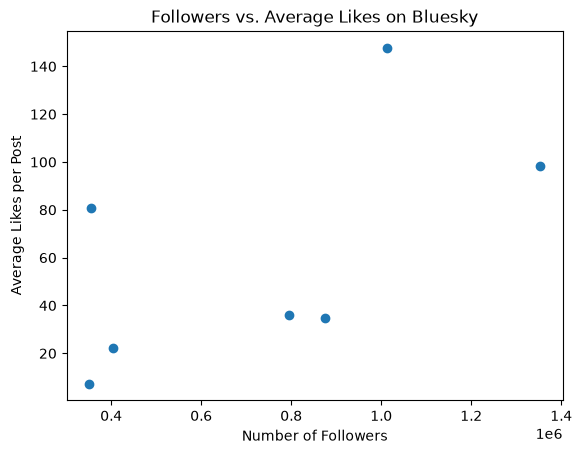

In [12]:

plt.scatter(df_final["Followers"], df_final["Average Likes"])

plt.xlabel("Number of Followers")
plt.ylabel("Average Likes per Post")
plt.title("Followers vs. Average Likes on Bluesky")

plt.show()


In [13]:

correlation = df_final["Followers"].corr(df_final["Average Likes"])

print("Correlation:", correlation)


Correlation: 0.5899527507921883


# Data Collection and Wrangling

For this project, I used two Bluesky API endpoints to collect information about followers and post engagement. I started with 8 news media accounts, but I was able to collect data from 7 of them, with a total of 70 posts.

I organized the information into two pandas DataFrames, one for follower counts and another for post likes. Then, I used groupby() and mean() to calculate the average likes for each account. Finally, I used pd.merge() to bring everything together into one table.

My final dataset includes the account names, number of followers, average likes per post, and number of posts analyzed.

# Results and Conclusions

After analyzing 7 accounts and 70 posts, I found a moderate positive relationship between the number of followers and average likes per post. The correlation was about 0.59, which suggests that accounts with more followers generally receive more likes.

However, this wasn't the case for every account. For example, NPR had fewer followers than The New York Times but received more likes on average. This shows that having more followers doesn't always mean getting more engagement.

Overall, my results somewhat support my hypothesis, but I think other factors besides follower count can also influence how many likes a post receives.

# Limitations and Next Steps

One limitation of my research is that I only looked at 7 accounts and 10 posts from each one. Since my sample was small and focused on news media accounts, the results might be different if I included other types of accounts.

Also, likes can depend on things like what the post is about, when it was published, or how long it has been online. The data can also change over time as accounts gain followers and posts receive more engagement.

If I continued this research, I would look at more accounts and posts and include other engagement metrics, such as comments and reposts, to get a better understanding of the relationship.